# PPE 탐지: baseline YOLO11n 직접 학습

수업 YOLO 노트북의 전이학습 흐름을 PPE 데이터에 적용합니다. 이 노트북은 **baseline 한 모델만** 학습하며, test 분할은 사용하지 않습니다. 학습 로그와 `best.pt`는 Google Drive에 저장됩니다.


## 1. 패키지와 GPU 확인
GPU 런타임을 선택한 상태에서 아래 셀을 순서대로 실행하세요.


In [1]:
!pip -q install ultralytics
import json, platform, torch, ultralytics
from pathlib import Path
from ultralytics import YOLO
assert torch.cuda.is_available(), "GPU 런타임이 아닙니다. Colab 런타임 설정에서 GPU를 선택하세요."
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__, "Ultralytics:", ultralytics.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
PyTorch: 2.14.1+cu130 Ultralytics: 8.4.208


## 2. 데이터 ZIP 연결
`construction-ppe-5class.zip`을 Google Drive의 **내 드라이브 최상위 폴더**에 올린 다음 실행하세요. 다른 위치에 올렸다면 `DATA_ZIP`만 고치면 됩니다.


In [2]:
from google.colab import drive
drive.mount("/content/drive")
DATA_ZIP = Path("/content/drive/MyDrive/construction-ppe-5class.zip")
assert DATA_ZIP.is_file(), f"ZIP을 찾지 못했습니다: {DATA_ZIP}"
print("ZIP 크기:", round(DATA_ZIP.stat().st_size / 1e6, 1), "MB")


Mounted at /content/drive
ZIP 크기: 647.8 MB


In [3]:
import zipfile, shutil, yaml
DATA_PARENT = Path("/content/ppe_project_data")
DATA_ROOT = DATA_PARENT / "construction-ppe-5class"
if not (DATA_ROOT / "split_manifest.csv").is_file():
    DATA_PARENT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(DATA_ZIP) as archive:
        assert archive.testzip() is None, "ZIP 파일이 손상되었습니다."
        archive.extractall(DATA_PARENT)
DATA_YAML = DATA_ROOT / "data_colab.yaml"
config = yaml.safe_load((DATA_ROOT / "data.yaml").read_text())
config["path"] = str(DATA_ROOT)
DATA_YAML.write_text(yaml.safe_dump(config, allow_unicode=True, sort_keys=False))
for split, expected in [("train", 800), ("val", 100), ("test", 100)]:
    actual = len(list((DATA_ROOT / "images" / split).glob("*.jpg")))
    assert actual == expected, (split, actual, expected)
    print(split, actual, "images")


train 800 images
val 100 images
test 100 images


## 3. 학습 설정과 환경 기록
첫 실험은 수업에서 비교한 YOLO11n의 사전학습 가중치를 PPE 데이터에 맞게 파인튜닝합니다. 나중에 비교할 모델도 같은 분할·시드·입력 크기·epoch·batch·증강 설정을 사용합니다.


In [4]:
RUN_ROOT = Path("/content/drive/MyDrive/ppe-project/runs")
RUN_NAME = "baseline_yolo11n_seed42"
RUN_DIR = RUN_ROOT / RUN_NAME
if RUN_DIR.exists():
    raise FileExistsError(f"기존 결과를 보호하려고 중단합니다: {RUN_DIR}")
RUN_ROOT.mkdir(parents=True, exist_ok=True)
SETTINGS = dict(data=str(DATA_YAML), epochs=60, imgsz=640, batch=8, device=0,
                seed=42, deterministic=True, workers=2, plots=True,
                fliplr=0.5, hsv_v=0.25, project=str(RUN_ROOT), name=RUN_NAME,
                exist_ok=False)
ENV = {"python": platform.python_version(), "torch": torch.__version__,
       "ultralytics": ultralytics.__version__, "gpu": torch.cuda.get_device_name(0),
       "model": "yolo11n.pt", "settings": SETTINGS}
print(json.dumps(ENV, ensure_ascii=False, indent=2))


{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "ultralytics": "8.4.208",
  "gpu": "Tesla T4",
  "model": "yolo11n.pt",
  "settings": {
    "data": "/content/ppe_project_data/construction-ppe-5class/data_colab.yaml",
    "epochs": 60,
    "imgsz": 640,
    "batch": 8,
    "device": 0,
    "seed": 42,
    "deterministic": true,
    "workers": 2,
    "plots": true,
    "fliplr": 0.5,
    "hsv_v": 0.25,
    "project": "/content/drive/MyDrive/ppe-project/runs",
    "name": "baseline_yolo11n_seed42",
    "exist_ok": false
  }
}


## 4. Baseline 학습
이 셀은 시간이 걸립니다. Colab 연결이 끊기지 않도록 실행 상태를 확인하세요.


In [5]:
model = YOLO("yolo11n.pt")
model.train(**SETTINGS)
assert (RUN_DIR / "weights" / "best.pt").is_file(), "best.pt가 저장되지 않았습니다."
assert (RUN_DIR / "results.csv").is_file(), "results.csv가 저장되지 않았습니다."
(RUN_DIR / "environment.json").write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
print("학습 완료:", RUN_DIR)
print("가중치:", RUN_DIR / "weights" / "best.pt")
print("로그:", RUN_DIR / "results.csv")


Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ppe_project_data/construction-ppe-5class/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.25, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_yolo11n_seed4

## 5. 학습 결과 확인
`results.png`, `confusion_matrix.png`, `results.csv`, `best.pt`가 Drive 결과 폴더에 저장됩니다. **test 분할 평가는 두 모델 학습과 최종 선택 절차를 정리한 뒤 한 번만 수행합니다.**


results.png


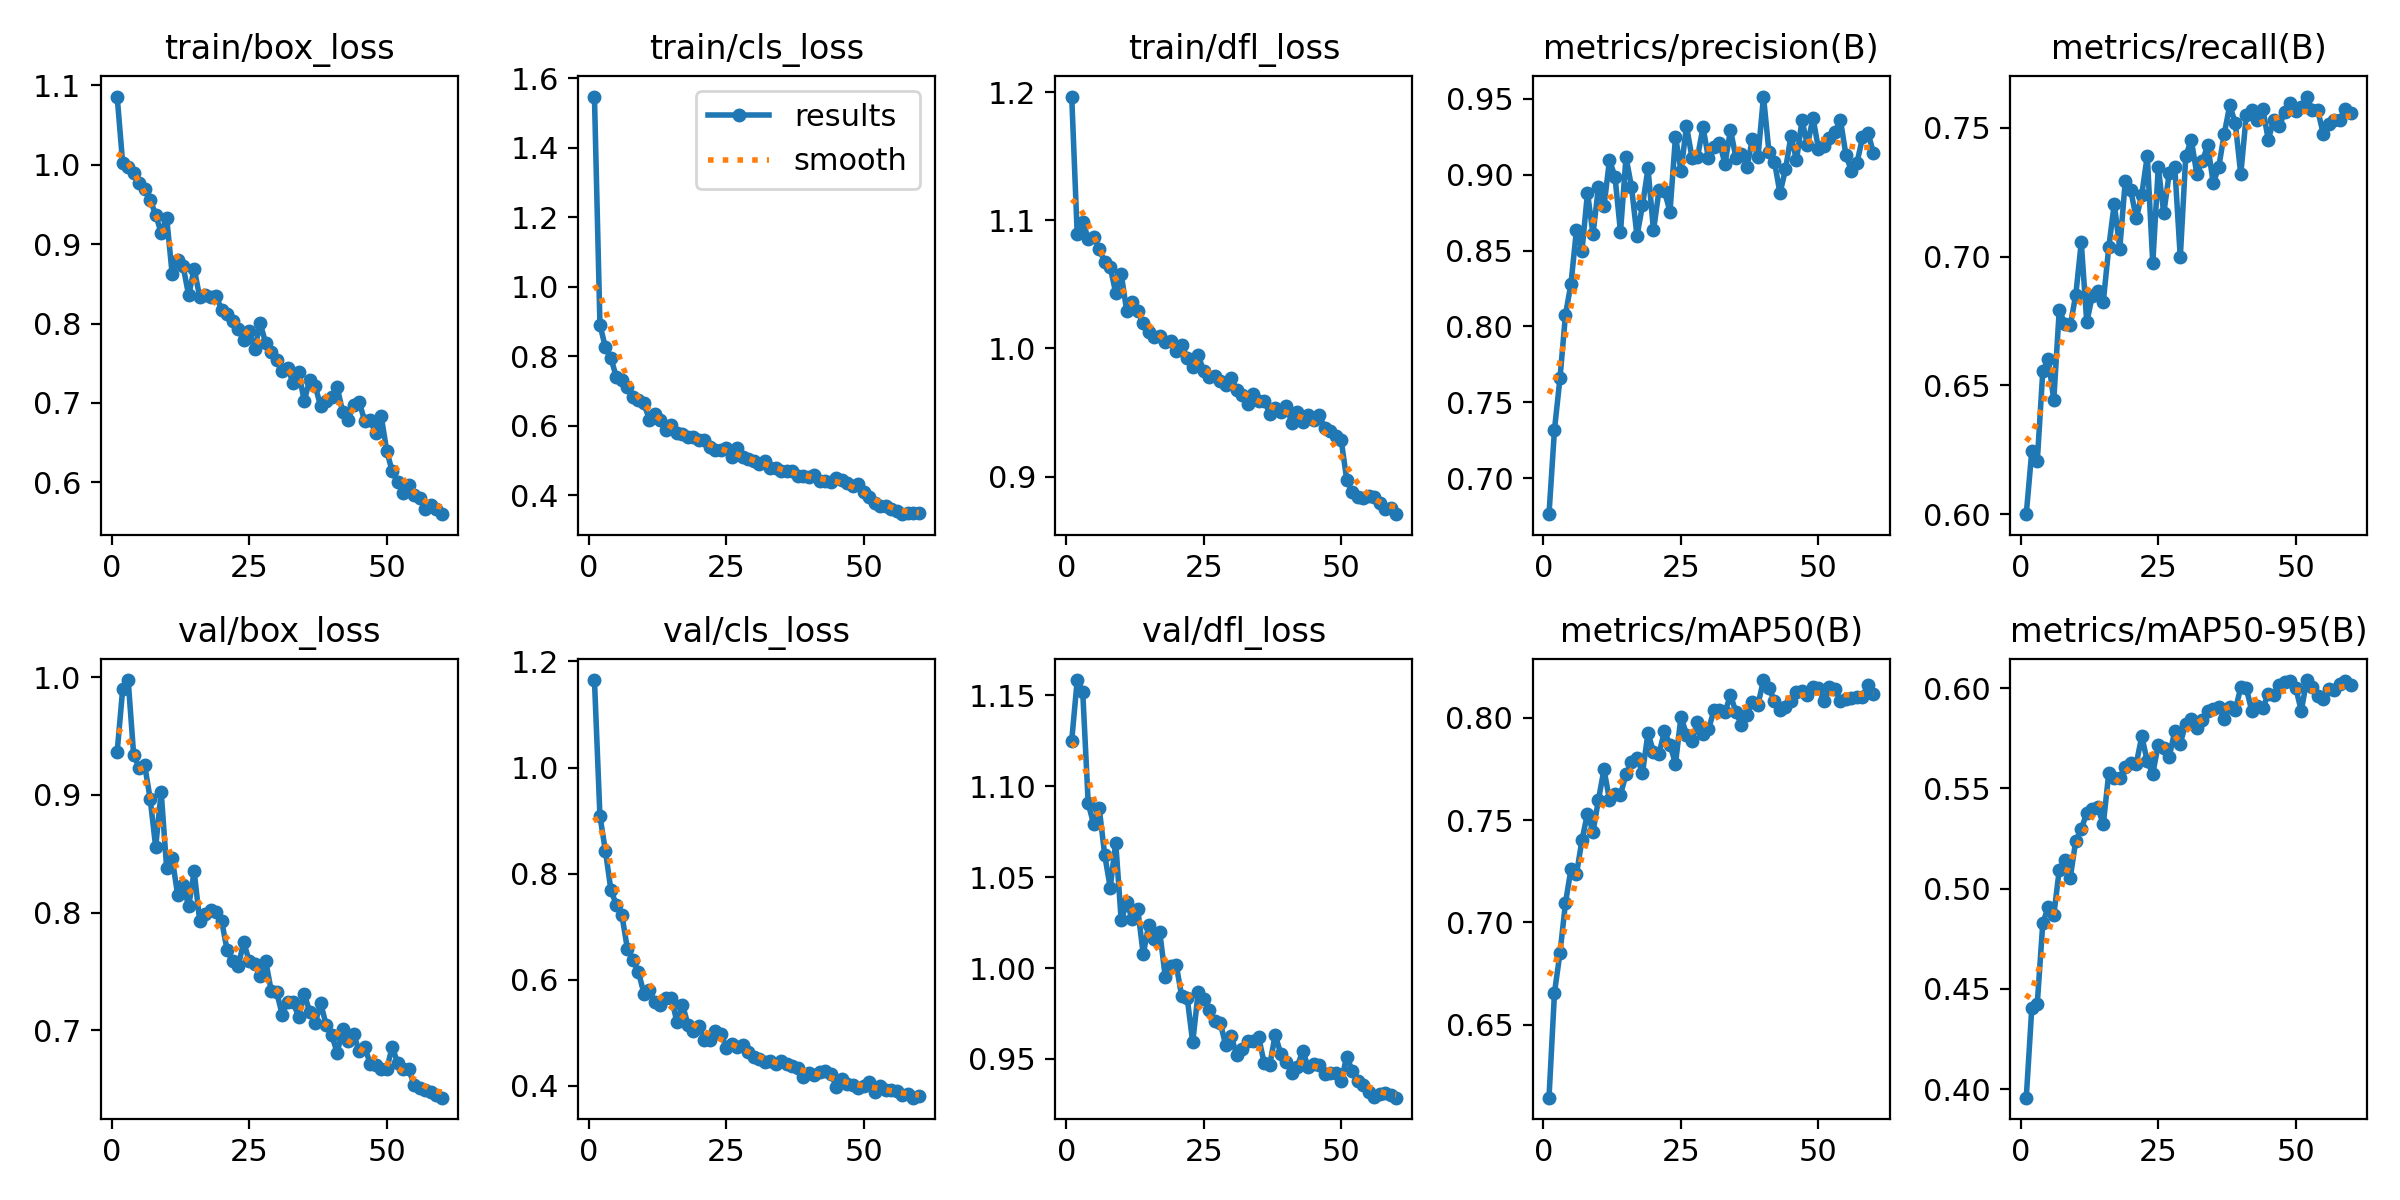

confusion_matrix.png


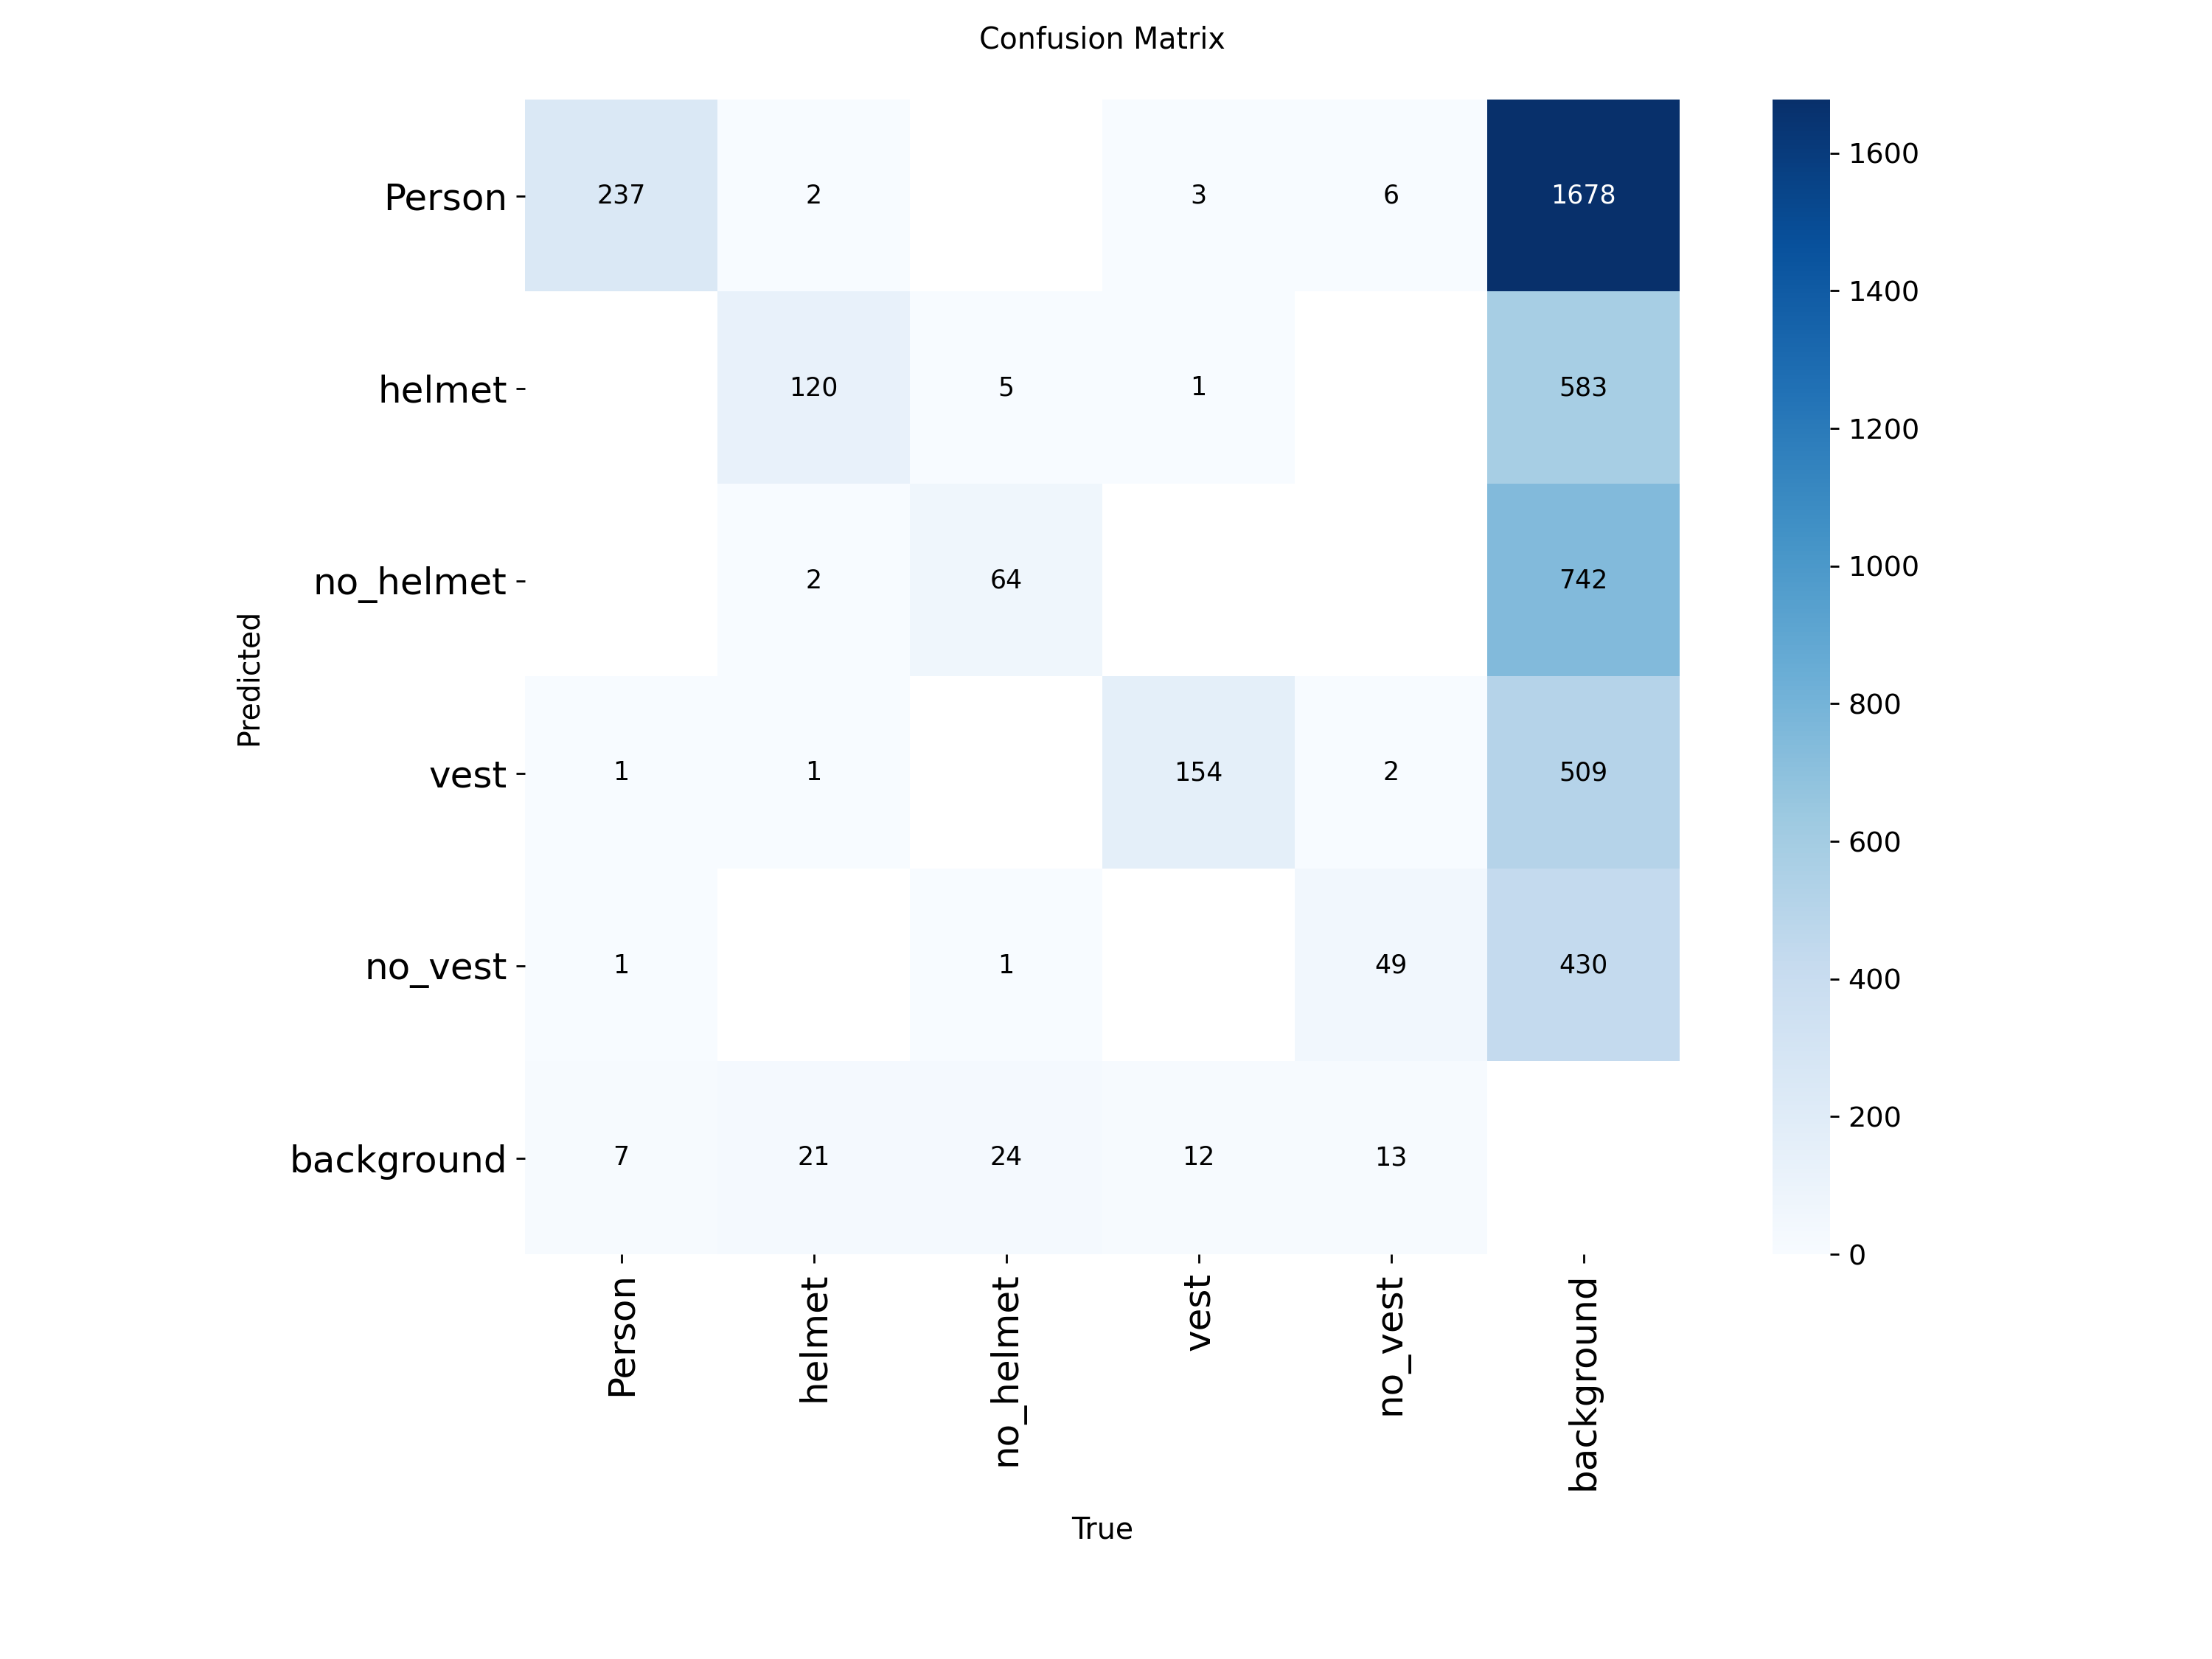

In [6]:
from IPython.display import display, Image as NotebookImage
for filename in ["results.png", "confusion_matrix.png"]:
    file = RUN_DIR / filename
    if file.is_file():
        print(filename)
        display(NotebookImage(filename=str(file), width=850))
    else:
        print("생성되지 않은 그림:", filename)
